In [4]:
import duckdb
con = duckdb.connect("../data/layoffs.duckdb")

In [11]:
# shape & nulls
con.execute("SELECT COUNT(*) FROM stg_layoffs").df()


,count_star()
0,4540


In [12]:
con.execute("""
SELECT 
  COUNT(*) AS total,
  COUNT(funds_raised) AS non_null_funds,
  COUNT(percentage_laid_off) AS non_null_pct,
  COUNT(stage) AS non_null_stage
FROM stg_layoffs
""").df()

,total,non_null_funds,non_null_pct,non_null_stage
0,4540,4003,2847,4532


In [13]:
con.execute("""
SELECT stage, 
       COUNT(*) AS total, 
       COUNT(percentage_laid_off) AS has_pct,
       ROUND(COUNT(percentage_laid_off) * 100.0 / COUNT(*), 1) AS pct_complete
FROM stg_layoffs
GROUP BY stage
ORDER BY total DESC
""").df()

,stage,total,has_pct,pct_complete
0,Post-IPO,1091,684,62.7
1,Unknown,764,449,58.8
2,Series B,491,329,67.0
3,Series C,452,286,63.3
4,Acquired,412,196,47.6
5,Series D,363,253,69.7
6,Series A,272,178,65.4
7,Series E,207,141,68.1
8,Seed,152,121,79.6
9,Series F,126,79,62.7


In [14]:
con.execute("""
SELECT 
  COUNT(*) AS total,
  COUNT(total_laid_off) AS has_total,
  ROUND(COUNT(total_laid_off) * 100.0 / COUNT(*), 1) AS pct_complete
FROM stg_layoffs
""").df()

,total,has_total,pct_complete
0,4540,2970,65.4


In [15]:
con.execute("""
SELECT 
  COUNT(*) AS total,
  COUNT(*) FILTER (WHERE percentage_laid_off IS NOT NULL OR total_laid_off IS NOT NULL) AS has_either,
  COUNT(*) FILTER (WHERE percentage_laid_off IS NOT NULL AND total_laid_off IS NOT NULL) AS has_both,
  COUNT(*) FILTER (WHERE percentage_laid_off IS NULL AND total_laid_off IS NULL) AS has_neither
FROM stg_layoffs
""").df()

,total,has_either,has_both,has_neither
0,4540,3799,2018,741


### Missingness in layoff severity columns

- `percentage_laid_off`: 62.7% complete
- `total_laid_off`: 65.4% complete
- Combined (either column present): **83.7%** is a meaningful improvement
- Neither present: 16.3% (741 rows) excluded from severity-based modeling,
  but may still be usable for the RAG corpus if a source URL exists

**Decision:** since neither column alone gives strong coverage, and combining 
them recovers a much larger usable pool, I'll build a binary target 
(`is_significant_layoff`) using whichever signal is available per row, 
rather than predicting an exact percentage. This also produces a cleaner 
"elevated risk" framing than a noisy regression target would.

In [16]:
# date range & density
con.execute("SELECT MIN(date), MAX(date), COUNT(DISTINCT date) FROM stg_layoffs").df()

,min(date),max(date),count(DISTINCT date)
0,2020-03-11,2026-07-31,1282


In [17]:
con.execute("""
SELECT 
  EXTRACT(YEAR FROM date_added) AS year,
  COUNT(*) AS num_events
FROM stg_layoffs
GROUP BY 1
ORDER BY 1
""").df()

,year,num_events
0,2020,630
1,2021,40
2,2022,1178
3,2023,1421
4,2024,645
5,2025,338
6,2026,288


### Layoffs by year

| Year | Events | Note |
|---|---|---|
| 2020 | 630 | Partial year (from March), COVID onset |
| 2021 | 40 | Sharp dip — plausibly real (tech hiring boom era), though can't rule out lower tracker coverage that year |
| 2022 | 1,178 | Correction begins |
| 2023 | 1,421 | Peak — post-boom layoff wave |
| 2024 | 645 | Declining |
| 2025 | 338 | Continued decline |
| 2026 | 288 | Partial year (through Jul 31) — annualizes to ~494, suggesting a mild uptick vs. 2025 |

**Takeaway:** the dataset reflects a real macro cycle (2021 boom → 2022–23 correction 
→ recent stabilization), not an artifact of tracking gaps, 2026 in particular is not 
under-covered once annualized. Any time-based model features should account for this 
cyclicality rather than assuming a flat trend.

In [9]:
# categorical distributions
con.execute("SELECT industry, COUNT(*) FROM stg_layoffs GROUP BY 1 ORDER BY 2 DESC").df()


,industry,count_star()
0,Finance,540
1,Retail,361
2,Healthcare,333
3,Consumer,312
4,Other,307
5,Transportation,274
6,Food,252
7,Marketing,219
8,Crypto,177
9,Real Estate,166


In [10]:
con.execute("SELECT stage, COUNT(*) FROM stg_layoffs GROUP BY 1 ORDER BY 2 DESC").df()

,stage,count_star()
0,Post-IPO,1091
1,Unknown,764
2,Series B,491
3,Series C,452
4,Acquired,412
5,Series D,363
6,Series A,272
7,Series E,207
8,Seed,152
9,Series F,126


### Industry & stage distributions

**Industry:** 31 categories, long tail, so no single industry dominates (top = Finance 
at 12%). Categories under ~50 rows (~1%) are candidates to bucket into "Other" for 
modeling: Energy, Fitness, AI, Manufacturing, Construction, Aerospace, Legal, None.
Note: "AI" as a labeled industry is small (35 rows), likely undercounts true AI-related 
companies, which get classified elsewhere (Data, Infrastructure, Consumer, etc.).

**Stage:** Post-IPO (24%) and Unknown (17%) dominate, together ~41% of rows. Unknown 
being the #2 category is a real limitation on stage as a predictive feature for a 
meaningful chunk of data. Clear funding-progression tail visible (Series A→J, declining 
counts as expected). Same-size "Other" bucketing candidates as industry: Series G/H/I/J, 
Subsidiary, None.

**Modeling implication:** both industry and stage will need a "bucket rare categories 
into Other" step before feature encoding, to avoid a model trying to learn from 
categories with a handful of examples.

In [8]:
# duplicate company name check
con.execute("SELECT company, COUNT(*) FROM stg_layoffs GROUP BY 1 ORDER BY 2 DESC LIMIT 20").df()

,company,count_star()
0,Amazon,22
1,Google,18
2,Microsoft,17
3,Salesforce,14
4,Intel,12
5,Rivian,12
6,Meta,12
7,Oracle,11
8,Expedia,10
9,TikTok,9


### Company name / duplicate check

Top companies (Amazon 22, Google 18, Microsoft 17, etc.) reflect **real repeated 
layoff events**, not duplicate records, since large companies had multiple distinct layoff rounds across 2020–2026. No fuzzy-duplicate naming issues visible in the top 20 (no split like "Google" vs "Google LLC").

Noted nuance: TikTok and Bytedance appear as separate entities (parent/subsidiary), left as-is for now, but worth remembering if ever aggregating to a parent-company level.

**Conclusion:** company field looks clean enough to use as-is; no cleaning step required before feature engineering.

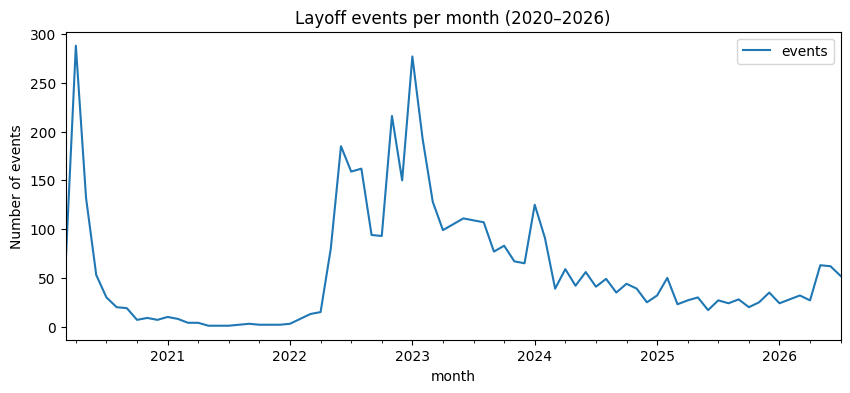

In [18]:
import matplotlib.pyplot as plt

# 1. Layoffs over time (monthly, smoother than daily)
monthly = con.execute("""
    SELECT DATE_TRUNC('month', date_added) AS month, COUNT(*) AS events
    FROM stg_layoffs
    GROUP BY 1 ORDER BY 1
""").df()
monthly.plot(x='month', y='events', figsize=(10,4), title='Layoff events per month (2020–2026)')
plt.ylabel('Number of events')
plt.show()

### Visualization: layoffs over time

Confirms the yearly breakdown visually, a sharp COVID spike (early 2020), a genuine trough through 2021, a dominant correction wave peaking in late 2022/early 2023, and a declining-then-stabilizing pattern into 2026. The clustering (layoffs aren't random across time, they wave in cycles) suggests time-based features (e.g. recent industry layoff rate, months since last wave) could add real predictive 
signal in Phase 2.

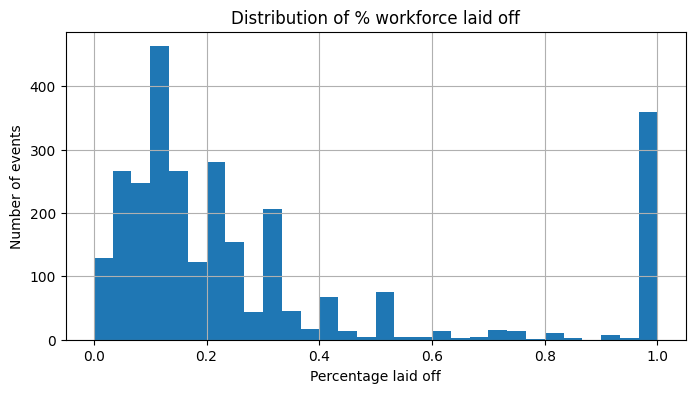

In [19]:
pct_df = con.execute("""
    SELECT percentage_laid_off 
    FROM stg_layoffs 
    WHERE percentage_laid_off IS NOT NULL
""").df()

pct_df['percentage_laid_off'].hist(bins=30, figsize=(8,4))
plt.title('Distribution of % workforce laid off')
plt.xlabel('Percentage laid off')
plt.ylabel('Number of events')
plt.show()

### Visualization: distribution of % laid off

Two distinct patterns visible: (1) a main cluster of partial layoffs, mostly between 0–35% of workforce, and (2) a separate spike of ~360 events at exactly 1.0 (100%), which almost certainly represents full company shutdowns rather than typical layoffs, which is a fundamentally different event type mixed into the same column. Worth treating 
100%-layoff events as an implicit "shutdown" flag, distinct from partial-layoff risk, if the project later wants to distinguish "at risk of cuts" from "at risk of closing."

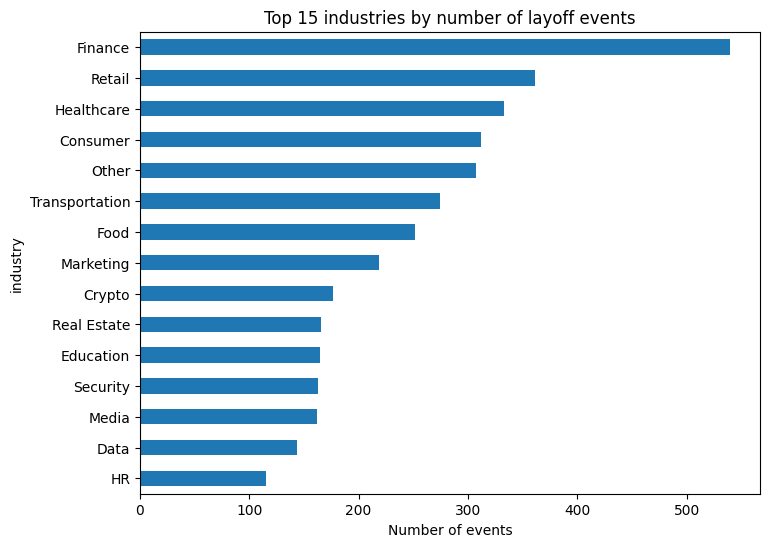

In [20]:
industry_df = con.execute("""
    SELECT industry, COUNT(*) AS events
    FROM stg_layoffs
    GROUP BY 1 ORDER BY 2 DESC LIMIT 15
""").df()

industry_df.plot(kind='barh', x='industry', y='events', figsize=(8,6), legend=False)
plt.title('Top 15 industries by number of layoff events')
plt.xlabel('Number of events')
plt.gca().invert_yaxis()
plt.show()

### Visualization: top industries by event count

Confirms a broad, cross-industry dataset rather than one dominated by a single sector, gradual decline from Finance (~540) down through the top 15, no sharp cliff. Reinforces the earlier bucketing plan: top ~10 industries (140+ events each) are solid standalone categories; the long tail below that should be grouped into "Other" for modeling.